In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np

perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0, 
     21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5, 
     22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5, 
     27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0, 
     36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0, 
     40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
     )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0, 
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0, 
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0, 
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0, 
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 
     1000.0, 1000.0]
     )

In [2]:
# 훈련데이터, 테스트데이터 분류
train_data, test_data, train_label, test_label = train_test_split(
perch_length, perch_weight, random_state=42)  # 회귀 : stratify 사용하지 않음

# sklearn은 2차원 배열을 사용, 그래서 훈련데이터, 테스트데이터를 2차원 배열로 변경
train_data = train_data.reshape(-1, 1)  # 1차원을 2차원 형태로 변경 - 2차원으로 입력이 되어야 함.
test_data = test_data.reshape(-1, 1)

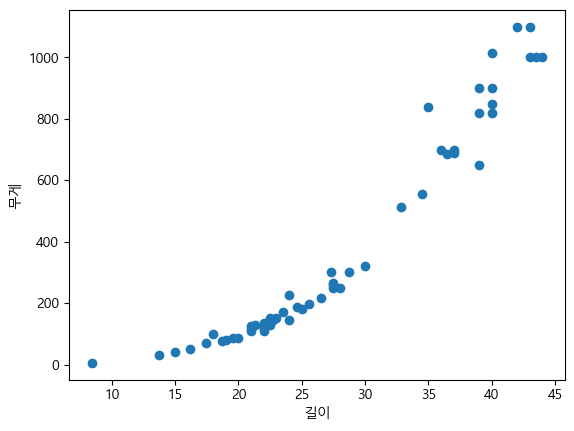

In [3]:
# 산점도 그래프
plt.scatter(perch_length,perch_weight)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [4]:
# 회귀모델 : Regressor, 분류모델 : Classifier 
# knr = KNeighborsRegressor()
knr = KNeighborsRegressor(n_neighbors=3)  # 기본값 : 5

# k-최근접 이웃 회귀 모델 적용
knr.fit(train_data, train_label)
# predict = knr.predict([[28.3]])
predict = knr.predict(test_data)
print("예측 결과값 : ",predict)
# 오차범위 - 평균절대값 오차 , 정답률이라는 것이 없고, 오차범위가 나옴.
mae = mean_absolute_error(test_label,predict)
print("오차범위(g) : ",mae)  # 19.157…
score = knr.score(train_data,train_label)
print("train정답률 :",score)
score2 = knr.score(test_data,test_label)
print("test정답률 :",score2)

예측 결과값 :  [  47.33333333   76.          247.66666667  120.          143.33333333
  921.66666667  275.          183.33333333  773.33333333  120.
 1033.33333333   62.66666667  275.          247.66666667]
오차범위(g) :  35.42380952380951
train정답률 : 0.9804899950518966
test정답률 : 0.9746459963987609


In [5]:
# 50cm 농어의 이웃을 구함, 예측이 제대로 되지 않음
distances, indexes = knr.kneighbors([[50]])

In [8]:
predict2 = knr.predict( [[50]] )           # 100cm로 변경해도 결과값이 같음.
print('50 예측:',predict2)
predict3 = knr.predict( [[100]] )
print('100 예측:',predict3)


50 예측: [1033.33333333]
100 예측: [1033.33333333]


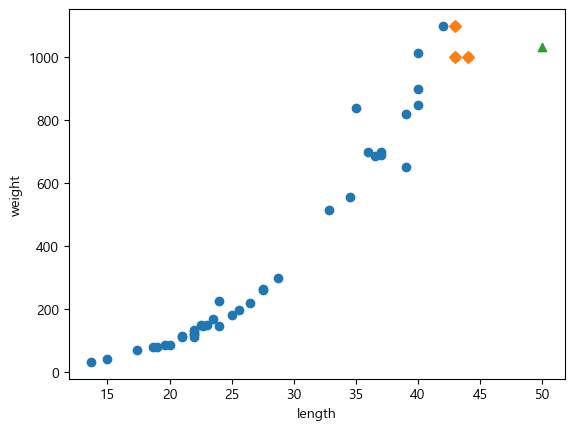

In [7]:
plt.scatter(train_data, train_label)
# 훈련 세트 중에서 이웃 샘플만 다시 그립니다
plt.scatter(train_data[indexes], train_label[indexes], marker='D')
# 50cm 농어 데이터
plt.scatter(50, 1033, marker='^')

plt.xlabel('length')
plt.ylabel('weight')
plt.show()